# Paper figures (revised paper)

Figures for the revised `confocal_paper.pdf`, following `PAPER_REVISION_PLAN.md`. Every figure is written to `data/gold_layer/paper_figures/`; no existing gold figure is overwritten.

* Data: silver layer `confocal_runs_processed_v2` (profiles, KDEs) and the results of the criterion version reported in the paper (`CRITERIA_VERSION`, currently **`objective_criteria_5`**, `processed_v2`). The criterion is **not** re-run here: the criterion figures are re-plotted from its `processed_v2/*.csv` files, so the classification is exactly the one of that version (checked at the end).
* Evaluated set: the 157 runs with $j_l \geq 0.035$ m/s, 7 reference classes (visual stratified evaluated as wavy).
* File names carry the figure number of the plan (they can change when the paper is written).

| Figure | File | Content |
|---|---|---|
| 6 | `fig06_tube_thickness_before_treatment.pdf` | $t_1$ per pattern, regular data |
| 7 | `fig07_tube_thickness_after_treatment.pdf` | $t_1$ per pattern, processed\_v2 |
| 8 | `fig08_mixer_wave_removal_run46.pdf` | mixer-wave removal, run 46 |
| 9 | `fig09_evaluated_region.pdf` | evaluated region on the Coleman and Garimella map |
| 10 | – | camera images: remove panel (d) stratified in LaTeX (no code) |
| 11 | `fig11_decision_tree.tex` / `.pdf` | decision tree of the criterion (TikZ) |
| 12-16 | `fig12a_...` to `fig16b_...` | film profiles (same runs as the current paper) |
| 17 | `fig17a_...`, `fig17b_...`, `fig17c_...` | churn and annular profiles, with the film recovered from $t_1$ |
| 18 | `fig18_bottom_film_by_pattern.pdf` | mean bottom film per pattern |
| 19 | `fig19_bottom_film_separated_zoom.pdf` | zoom on the separated patterns |
| 20 | `fig20_kde_by_pattern.pdf` (+ `fig20a_...` to `fig20f_...`) | PDF of $t_2$ per pattern, including churn |
| 21 | `fig21a_criterion_family.pdf`, `fig21b_criterion_intermittent.pdf` | criterion, intermittent family |
| 22 | `fig22a_...` to `fig22d_...` | criterion, separated family |
| 23 | `fig23_confusion_matrix.pdf` | confusion matrix (same order on both axes) |
| 24 | `fig24a_flow_pattern_map_visual.pdf`, `fig24b_flow_pattern_map_objective.pdf` | visual vs. objective map |
| 25 | `fig25_sensitivity_thresholds.pdf` | threshold sensitivity |

In [1]:
import json
import shutil
import subprocess
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

from IPython.display import display

from src.boxplots import boxplot_plot
from src.plot_flow_pattern_maps import map_garimella, map_garimella_region
from src.flow_pattern_criteria import (
    load_run,
    film_estimate,
    balanced_accuracy,
    reference_pattern,
    JL_MIN,
    OBJECTIVE_PATTERNS,
)
from src.flow_pattern_report import (
    pattern_styles,
    criterion_scatter,
    confusion_heatmap,
    sweep_figure,
    profile_comparison_figure,
    VISUAL_PATTERNS,
    _densest_window,
)

In [2]:
# =========================================================
# Matplotlib style (same as kde_plots.ipynb)
# =========================================================

params = {
    "ytick.color": "black",
    "xtick.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Serif"],
}

plt.rcParams.update(params)

# Flow pattern maps (same as flow_pattern_maps.ipynb)
MAP_RC = {
    "font.serif": ["Computer Modern Roman"],
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
}

# Film profiles (same as profile_pic_v2.ipynb)
PROFILE_RC = {
    "font.serif": ["Computer Modern Roman"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
}

CM = 1 / 2.54

## Data

All results come from `CRITERIA_VERSION` (`processed_v2`). The pattern order and the box colours are the same in every figure.

In [3]:
silver_root = project_root / 'data/silver_layer'
gold_root = project_root / 'data/gold_layer'

CRITERIA_VERSION = 'objective_criteria_5'   # version reported in the paper (runs 10-12 relabelled churn)
criteria_path = gold_root / CRITERIA_VERSION
results_path = criteria_path / 'processed_v2'

out = gold_root / 'paper_figures'
out.mkdir(exist_ok=True)

RUNS = {
    'regular': silver_root / 'confocal_runs',
    'processed': silver_root / 'confocal_runs_processed',
    'processed_v2': silver_root / 'confocal_runs_processed_v2',
}

manifest = json.loads((criteria_path / 'run_manifest.json').read_text())
P = manifest['criterion_params']
F = manifest['feature_params']

df_experimental = pd.read_pickle(silver_root / 'experimental_results.pkl')

# Features and objective pattern of the 157 evaluated runs (reduced_pattern = reference class)
features = pd.read_csv(results_path / 'objective_flow_pattern.csv', index_col=0)

# Evaluated runs with the reference classes (visual stratified -> wavy)
df_eval = df_experimental[df_experimental['jl'] >= JL_MIN].copy()
df_eval['visual_pattern'] = df_eval['reduced_pattern']
df_eval['reduced_pattern'] = reference_pattern(df_eval['reduced_pattern'])
eval_rows = df_eval.set_index('run_id')

assert len(df_eval) == len(features) == 157

# Pattern order and colours used in every figure
PATTERNS = [p for p in VISUAL_PATTERNS if p != 'stratified']
BOX_COLORS = dict(zip(PATTERNS, ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#937860', '#8C8C8C']))

# Marker / colour per pattern, as in the flow pattern maps and the criterion figures of kde_plots.ipynb
map_categories = list(df_experimental['reduced_pattern'].unique())
styles = pattern_styles(map_categories)

saved = []


def save(fig, name):
    path = out / f'{name}.pdf'
    fig.savefig(path, format='pdf', bbox_inches='tight')
    saved.append(path.name)
    return fig


df_eval['reduced_pattern'].value_counts().loc[PATTERNS]

reduced_pattern
bubbly       11
plug         33
slug         25
dispersed    20
churn        14
wavy         44
annular      10
Name: count, dtype: int64

## Section 2.5: data treatment

**Figs. 6 and 7**: mean tube thickness $t_1$ per pattern before (regular data) and after (processed\_v2) the treatment, for the 157 evaluated runs. The old figures used the 53-run subset (Fig. 7 had only 5 patterns).

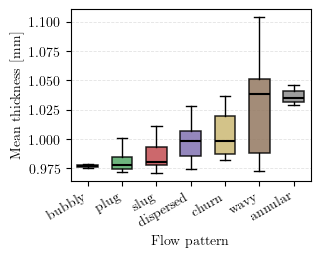

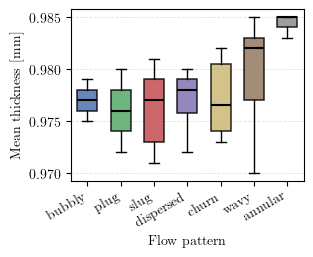

In [4]:
results = {
    'regular': pd.read_pickle(silver_root / 'confocal_results.pkl'),
    'processed_v2': pd.read_pickle(silver_root / 'confocal_results_processed_v2.pkl'),
}

for variant, name in [
    ('regular', 'fig06_tube_thickness_before_treatment'),
    ('processed_v2', 'fig07_tube_thickness_after_treatment'),
]:

    df = df_eval.merge(results[variant], on='run_id')

    fig, ax = boxplot_plot(
        df, 't1_mean', 'Mean thickness', 'mm',
        patterns=PATTERNS, colors=[BOX_COLORS[p] for p in PATTERNS], rotation=30,
    )

    save(fig, name)
    display(fig)

**Fig. 8**: profile of run 46 (wavy, 1.35 kHz) before and after the mixer-wave removal.

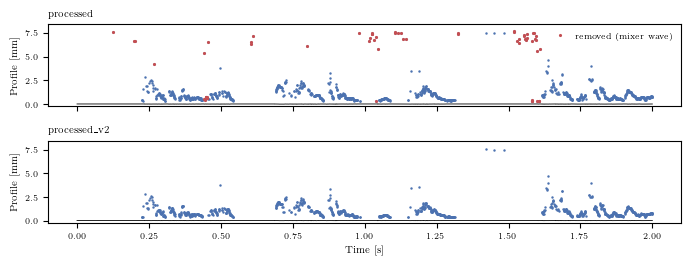

In [5]:
fig = profile_comparison_figure(
    load_run(46, RUNS['processed']),
    load_run(46, RUNS['processed_v2']),
    t_max=2.0,
)

save(fig, 'fig08_mixer_wave_removal_run46')
display(fig)

## Section 2.6: experimental range

**Fig. 9**: evaluated region (157 runs) on the Coleman and Garimella map. **Fig. 10** (camera images) needs no code: remove panel (d) stratified in LaTeX.

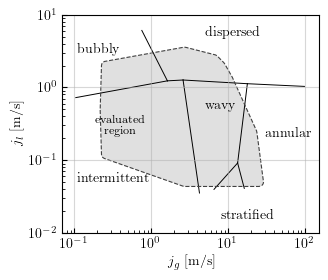

In [6]:
with plt.rc_context(MAP_RC):

    fig, ax = map_garimella_region(df_experimental[df_experimental['jl'] >= JL_MIN])

    save(fig, 'fig09_evaluated_region')
    display(fig)

## Section 3: objective criterion

**Fig. 11**: decision tree, written as a TikZ file (`fig11_decision_tree.tex`, to `\input` in the paper or to compile alone) with the thresholds of `CRITERIA_VERSION`. A PDF is compiled when `pdflatex` is available.

In [7]:
TREE_TEX = r"""\documentclass[border=2pt]{standalone}
\usepackage{amsmath}
\usepackage{tikz}
\usetikzlibrary{arrows.meta, positioning}

\begin{document}
\begin{tikzpicture}[
    dec/.style={draw, rounded corners=2pt, align=center, font=\footnotesize, inner sep=3pt, text width=3.6cm},
    result/.style={draw, fill=gray!15, align=center, font=\footnotesize\bfseries, minimum width=1.5cm, minimum height=0.55cm},
    arr/.style={-{Stealth[length=1.6mm]}, semithick},
    lab/.style={font=\scriptsize, fill=white, inner sep=1pt},
]

% Start and family test
\node[dec, text width=5.4cm] (start) at (0, 0) {Confocal record\\ + mean $(dp/dz)_{tp}$ of the run};
\node[dec, text width=5.4cm] (bridge) at (0, -1.45) {Liquid bridges\\ ($t_2 \geq <H_LIQ>$~mm for $\geq <DWELL>$~ms)\\ $f_\mathrm{bridge} \geq <F_BRIDGE>$~Hz?};

% Intermittent family
\node[dec, text width=3.0cm] (bub) at (-4.0, -2.9) {$\text{Bubble share} \geq <BUBBLE>$?};
\node[result] (bubbly) at (-5.5, -4.4) {Bubbly};
\node[dec, text width=3.2cm] (plugq) at (-2.6, -4.4) {$\text{Mean bridge} \geq <PLUG_MS>$~ms\\ and $f_\mathrm{liquid} \geq <PLUG_FL>$?};
\node[result] (plug) at (-3.6, -5.9) {Plug};
\node[result] (slug) at (-1.6, -5.9) {Slug};

% Separated family
\node[dec, text width=3.9cm] (ann) at (3.4, -2.9) {Bottom film\\ $\text{mean} < <ANN_MEAN>$~mm and $\text{std} < <ANN_STD>$~mm?};
\node[result] (annular) at (7.3, -2.9) {Annular};
\node[dec, text width=3.9cm] (agit) at (3.4, -4.95) {Agitated film?\\ $\geq <PEAKS>$ KDE peaks, or\\ ($\text{mean} \geq <DISP_MEAN>$~mm, jump fraction $\geq <DISP_JUMP>$, detected $\geq <DISP_DET>\,\%$)\\ and $(dp/dz)_{tp}/(dp/dz)_h \geq <HOMOG>$};
\node[dec, text width=3.9cm] (liq) at (3.4, -7.35) {Liquid-rich film?\\ $\text{mean} < <LR_FILM>$~mm,\\ $(dp/dz)_{tp}/(dp/dz)_h \geq <HOMOG>$\\ and $\phi_l^2 \leq <LR_PHI2>$};
\node[result] (wavy) at (3.4, -9.0) {Wavy};
\node[dec, text width=2.6cm] (split) at (7.3, -6.15) {$\geq <PEAKS>$ KDE peaks\\ or $\phi_l^2 \leq <DISP_PHI2>$?};
\node[result] (churn) at (6.35, -7.75) {Churn};
\node[result] (dispersed) at (8.25, -7.75) {Dispersed};

% Arrows
\draw[arr] (start) -- (bridge);
\draw[arr] (bridge.west) -| node[lab, pos=0.72] {yes: intermittent} (bub.north);
\draw[arr] (bridge.east) -| node[lab, pos=0.72] {no: separated} (ann.north);

\draw[arr] ([xshift=-6mm]bub.south) -- node[lab] {yes} (bubbly.north);
\draw[arr] ([xshift=6mm]bub.south) -- node[lab] {no} (plugq.north);
\draw[arr] ([xshift=-5mm]plugq.south) -- node[lab] {yes} (plug.north);
\draw[arr] ([xshift=5mm]plugq.south) -- node[lab] {no} (slug.north);

\draw[arr] (ann.east) -- node[lab] {yes} (annular.west);
\draw[arr] (ann.south) -- node[lab] {no} (agit.north);
\draw[arr] (agit.south) -- node[lab] {no} (liq.north);
\draw[arr] (liq.south) -- node[lab] {no} (wavy.north);
\draw[arr] (agit.east) -- node[lab, above, sloped] {yes} (split.north west);
\draw[arr] (liq.east) -- node[lab, below, sloped] {yes} (split.south west);
\draw[arr] ([xshift=-4mm]split.south) -- node[lab] {no} (churn.north);
\draw[arr] ([xshift=4mm]split.south) -- node[lab] {yes} (dispersed.north);

\end{tikzpicture}
\end{document}
"""

thresholds = {
    '<H_LIQ>': f"{F['h_liq']:g}",
    '<DWELL>': f"{1000 * F['min_dwell']:g}",
    '<F_BRIDGE>': f"{P['f_bridge_hz']:g}",
    '<BUBBLE>': f"{P['bubble_share_min']:g}",
    '<PLUG_MS>': f"{1000 * P['plug_min_duration']:g}",
    '<PLUG_FL>': f"{P['plug_min_f_liquid']:.2f}",
    '<ANN_MEAN>': f"{P['annular_max_mean']:g}",
    '<ANN_STD>': f"{P['annular_max_std']:g}",
    '<PEAKS>': f"{P['dispersed_min_peaks']:g}",
    '<DISP_MEAN>': f"{P['dispersed_min_mean']:g}",
    '<DISP_JUMP>': f"{P['dispersed_min_jump']:g}",
    '<DISP_DET>': f"{100 * P['dispersed_min_detected']:g}",
    '<HOMOG>': f"{P['agitated_min_homog_ratio']:g}",
    '<DISP_PHI2>': f"{P['dispersed_max_phi2']:g}",
    '<LR_FILM>': f"{P['liquid_rich_max_film']:g}",
    '<LR_PHI2>': f"{P['liquid_rich_max_phi2']:g}",
}

tex = TREE_TEX

for key, value in thresholds.items():
    tex = tex.replace(key, value)

tex_path = out / 'fig11_decision_tree.tex'
tex_path.write_text(tex, encoding='utf-8')
saved.append(tex_path.name)

if shutil.which('pdflatex'):

    build = out / '_build'
    build.mkdir(exist_ok=True)

    subprocess.run(
        ['pdflatex', '-interaction=nonstopmode', '-halt-on-error', '-output-directory', str(build), str(tex_path)],
        check=True, capture_output=True, timeout=300,
    )

    shutil.copy(build / 'fig11_decision_tree.pdf', out / 'fig11_decision_tree.pdf')
    shutil.rmtree(build)
    saved.append('fig11_decision_tree.pdf')

thresholds

{'<H_LIQ>': '7.5',
 '<DWELL>': '5',
 '<F_BRIDGE>': '0.1',
 '<BUBBLE>': '0.5',
 '<PLUG_MS>': '20',
 '<PLUG_FL>': '0.10',
 '<ANN_MEAN>': '0.1',
 '<ANN_STD>': '0.2',
 '<PEAKS>': '2',
 '<DISP_MEAN>': '0.4',
 '<DISP_JUMP>': '0.4',
 '<DISP_DET>': '15',
 '<HOMOG>': '1',
 '<DISP_PHI2>': '5',
 '<LR_FILM>': '0.5',
 '<LR_PHI2>': '15'}

## Section 4.1: film thickness profiles

**Figs. 12-16**: the runs of the current paper (old Figs. 10-14), now from processed\_v2, same windows (0.5 s for bubbly, 1 s otherwise). The black line is the inner wall ($t_1$ minus the glass thickness), the blue line the detected interface $t_2$. In run 44 (Fig. 16b) the spur at 0.95 s was a mixer wave and is now removed.

Note: the dispersed examples (runs 8, 9) are classified as **churn** by the criterion and the slug example (run 67) as **plug** (Table 12 of the plan). Change `PROFILE_RUNS` to use other examples.

**Fig. 17**: churn and annular profiles. They also show the film below the detection limit recovered from $t_1$ (orange, Eq. 9). The 1 s window with the most detected samples is shown.

fig12a_profile_bubbly_run65


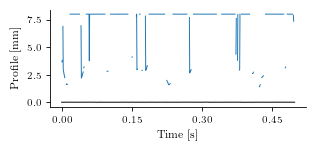

fig12b_profile_bubbly_run59


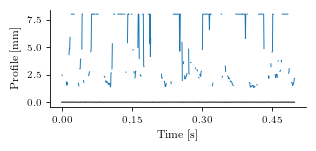

fig13a_profile_plug_run33


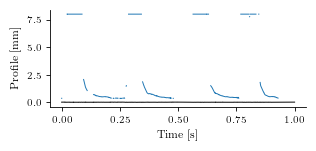

fig13b_profile_plug_run28


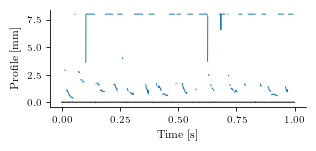

fig14a_profile_slug_run67


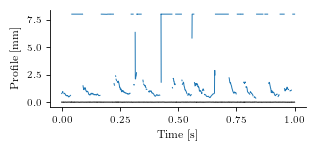

fig14b_profile_slug_run56


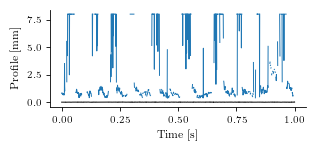

fig15a_profile_dispersed_run8


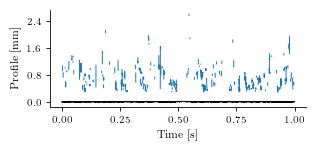

fig15b_profile_dispersed_run9


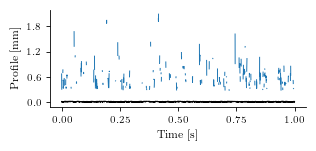

fig16a_profile_wavy_run45


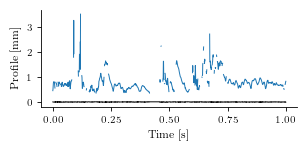

fig16b_profile_wavy_run44


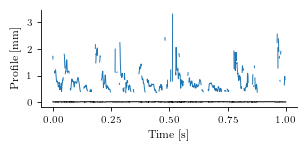

,file,run_id,jl,jg,reference,objective
0,fig12a_profile_bubbly_run65,65,0.97,0.52,bubbly,bubbly
1,fig12b_profile_bubbly_run59,59,1.48,0.52,bubbly,bubbly
2,fig13a_profile_plug_run33,33,0.24,0.52,plug,plug
3,fig13b_profile_plug_run28,28,0.79,0.52,plug,plug
4,fig14a_profile_slug_run67,67,0.97,1.30,slug,plug
5,fig14b_profile_slug_run56,56,1.50,1.31,slug,slug
6,fig15a_profile_dispersed_run8,8,1.45,4.78,dispersed,churn
7,fig15b_profile_dispersed_run9,9,1.38,6.80,dispersed,churn
8,fig16a_profile_wavy_run45,45,0.20,5.33,wavy,wavy
9,fig16b_profile_wavy_run44,44,0.29,5.38,wavy,wavy


In [8]:
GLASS_THICKNESS = 0.96
INTERFACE_COLOR = '#1f77b4'
T1_FILM_COLOR = '#DD8452'


def profile_figure(df, t_start=0.0, t_max=1.0, film_from_t1=False, show_states=False):
    """
    Film profile in the style of the current paper (8.4 x 3.2 cm). With
    ``film_from_t1`` the film below the detection limit (bottom film
    estimate, needs ``t1_raw``) is added as dots; ``show_states`` draws the
    film / liquid state heights.
    """

    df = df[(df['time'] >= t_start) & (df['time'] <= t_start + t_max)].copy()
    df['time'] = df['time'] - t_start

    with plt.rc_context(PROFILE_RC):

        fig, ax = plt.subplots(figsize=(8.4 * CM, 3.2 * CM))

        ax.plot(df['time'].to_numpy(), (df['t1'] - GLASS_THICKNESS).to_numpy(), color='black', linewidth=0.7)
        ax.plot(df['time'].to_numpy(), df['t2'].to_numpy(), color=INTERFACE_COLOR, linewidth=0.7, label='detected $t_2$')

        if film_from_t1:
            estimate = film_estimate(df)
            merged = df['t2'].isna().to_numpy() & ~np.isnan(estimate)
            ax.plot(df['time'].to_numpy()[merged], estimate[merged], '.', color=T1_FILM_COLOR, markersize=1.5,
                    label='film below detection (from $t_1$)')
            ax.legend(fontsize=6, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
                      markerscale=3, handlelength=1.5)

        if show_states:
            for height in (F['h_film'], F['h_liq']):
                ax.axhline(height, color='0.5', linestyle=':', linewidth=0.5)

        ax.set_xlabel('Time [s]')
        ax.set_ylabel('Profile [mm]')
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        plt.close(fig)

    return fig


def save_profile(fig, name):
    with plt.rc_context(PROFILE_RC):
        save(fig, name)


# (file name, run, window [s]) - same runs as old Figs. 10-14
PROFILE_RUNS = [
    ('fig12a_profile_bubbly_run65', 65, 0.5),
    ('fig12b_profile_bubbly_run59', 59, 0.5),
    ('fig13a_profile_plug_run33', 33, 1.0),
    ('fig13b_profile_plug_run28', 28, 1.0),
    ('fig14a_profile_slug_run67', 67, 1.0),
    ('fig14b_profile_slug_run56', 56, 1.0),
    ('fig15a_profile_dispersed_run8', 8, 1.0),
    ('fig15b_profile_dispersed_run9', 9, 1.0),
    ('fig16a_profile_wavy_run45', 45, 1.0),
    ('fig16b_profile_wavy_run44', 44, 1.0),
]

profile_table = []

for name, run_id, window in PROFILE_RUNS:

    fig = profile_figure(load_run(run_id, RUNS['processed_v2']), t_max=window)
    save_profile(fig, name)

    row = features.set_index('run_id').loc[run_id]
    profile_table.append({'file': name, 'run_id': run_id, 'jl': row['jl'], 'jg': row['jg'],
                          'reference': row['reduced_pattern'], 'objective': row['objective_pattern']})

    print(name)
    display(fig)

pd.DataFrame(profile_table)

fig17a_profile_churn_run93: jl = 1.11, jg = 3.95 m/s, window starts at 3.68 s, reference churn, objective churn


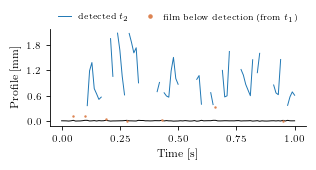

fig17b_profile_churn_liquid_rich_run1: jl = 0.92, jg = 5.83 m/s, window starts at 17.24 s, reference churn, objective churn


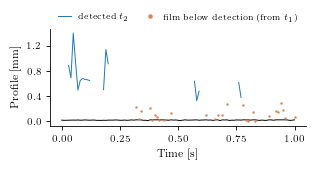

fig17c_profile_annular_run85: jl = 0.14, jg = 20.95 m/s, window starts at 14.45 s, reference annular, objective annular


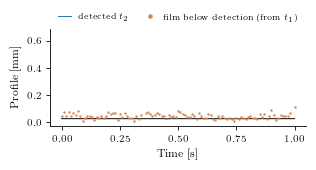

In [9]:
# Fig. 17: churn and annular profiles with the film recovered from t1
CHURN_ANNULAR_RUNS = [
    ('fig17a_profile_churn_run93', 93),
    ('fig17b_profile_churn_liquid_rich_run1', 1),
    ('fig17c_profile_annular_run85', 85),
]

for name, run_id in CHURN_ANNULAR_RUNS:

    df_run = load_run(run_id, RUNS['processed_v2'], raw_path=RUNS['regular'])
    start = _densest_window(df_run, 1.0)

    fig = profile_figure(df_run, t_start=start, t_max=1.0, film_from_t1=True)
    save_profile(fig, name)

    row = features.set_index('run_id').loc[run_id]
    print(f"{name}: jl = {row['jl']:.2f}, jg = {row['jg']:.2f} m/s, window starts at {start:.2f} s, "
          f"reference {row['reduced_pattern']}, objective {row['objective_pattern']}")
    display(fig)

## Section 4.2: bottom film by pattern

**Fig. 18**: mean bottom film estimate per pattern (Eq. 9: detected $t_2$ below 7.5 mm, or the film merged with the wall reading). It excludes the liquid bridges and includes the films below the detection limit. **Fig. 19**: zoom on the separated patterns, same colours.

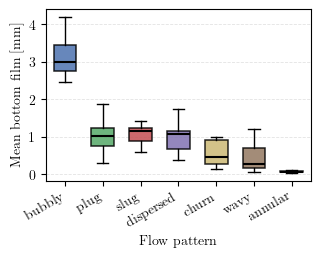

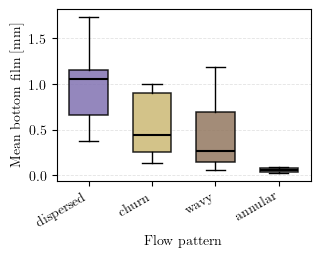

reduced_pattern
bubbly       2.984
plug         1.011
slug         1.143
dispersed    1.054
churn        0.445
wavy         0.271
annular      0.055
Name: film_est_mean_mm, dtype: float64

In [10]:
fig, ax = boxplot_plot(
    features, 'film_est_mean_mm', 'Mean bottom film', 'mm',
    patterns=PATTERNS, colors=[BOX_COLORS[p] for p in PATTERNS], rotation=30,
)
save(fig, 'fig18_bottom_film_by_pattern')
display(fig)

separated = ['dispersed', 'churn', 'wavy', 'annular']

fig, ax = boxplot_plot(
    features, 'film_est_mean_mm', 'Mean bottom film', 'mm',
    patterns=separated, colors=[BOX_COLORS[p] for p in separated], rotation=30,
)
save(fig, 'fig19_bottom_film_separated_zoom')
display(fig)

features.groupby('reduced_pattern')['film_est_mean_mm'].median().loc[PATTERNS].round(3)

## Section 4.3: PDF of the film thickness

**Fig. 20**: KDE (Gaussian, Scott bandwidth, as in the criterion) of the detected $t_2$, processed\_v2 (mixer waves excluded), six runs per pattern. Same runs as the current paper, except run 40 (now outside the evaluated region), replaced by run 45 (the run of Fig. 16a), and a new churn panel. Annular has no panel: almost no $t_2$ is detected. The multi-panel figure and the single panels are both saved.

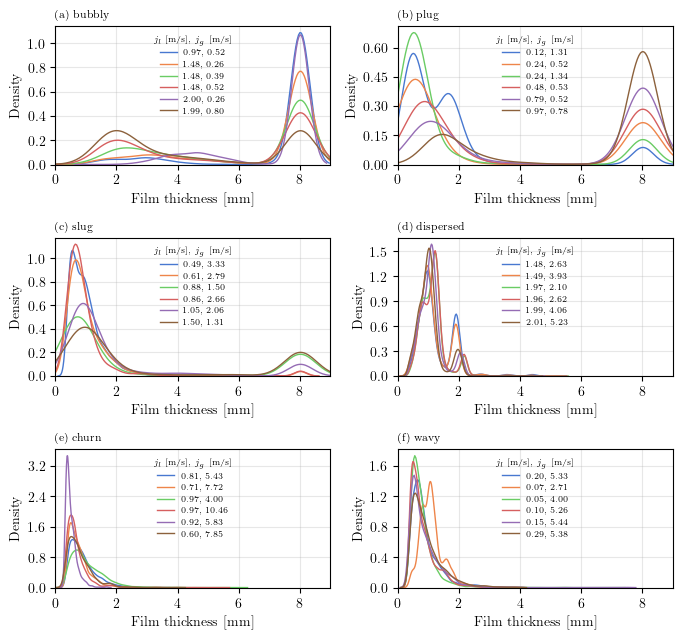

In [11]:
KDE_RUNS = {
    'bubbly': [65, 61, 60, 59, 50, 53],
    'plug': [35, 33, 36, 31, 28, 66],
    'slug': [15, 14, 13, 25, 87, 56],
    'dispersed': [81, 80, 74, 75, 76, 77],
    'churn': [26, 27, 94, 138, 1, 140],
    'wavy': [45, 41, 148, 47, 46, 44],
}

for pattern, run_ids in KDE_RUNS.items():
    assert (eval_rows.loc[run_ids, 'reduced_pattern'] == pattern).all(), pattern


def kde_axes(ax, run_ids, title=None):

    palette = sns.color_palette('muted', len(run_ids))

    for color, run_id in zip(palette, run_ids):

        t2 = load_run(run_id, RUNS['processed_v2'])['t2'].dropna()
        row = eval_rows.loc[run_id]

        sns.kdeplot(x=t2, ax=ax, color=color, linewidth=1.0, label=f"{row['jl']:.2f}, {row['jg']:.2f}", zorder=2)

    ax.set_xlim(0, 9)
    ax.set_xlabel('Film thickness [mm]')
    ax.set_ylabel('Density')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(alpha=0.3, zorder=0)
    ax.legend(title=r'$j_l$ [m/s], $j_g$ [m/s]', loc='upper center', bbox_to_anchor=(0.5, 0.98),
              frameon=False, fontsize=6, title_fontsize=6)

    if title is not None:
        ax.set_title(title, loc='left', fontsize=8)


# Multi-panel figure
fig, axes = plt.subplots(3, 2, figsize=(17.6 * CM, 16.5 * CM))

for ax, letter, (pattern, run_ids) in zip(axes.flat, 'abcdef', KDE_RUNS.items()):
    kde_axes(ax, run_ids, title=f'({letter}) {pattern}')

fig.tight_layout()
plt.close(fig)

save(fig, 'fig20_kde_by_pattern')
display(fig)

# Single panels (8.4 x 6.8 cm, as the current Figs. 17-21)
for letter, (pattern, run_ids) in zip('abcdef', KDE_RUNS.items()):

    fig, ax = plt.subplots(figsize=(8.4 * CM, 6.8 * CM))
    kde_axes(ax, run_ids)
    fig.tight_layout()
    plt.close(fig)

    save(fig, f'fig20{letter}_kde_{pattern}')

## Section 4.4: feature planes of the criterion

Re-plotted from the features of `CRITERIA_VERSION`, with the same code as `kde_plots.ipynb`. Change in **Fig. 22d** (liquid-rich branch): only the runs discussed in the text are labelled, and the x axis is widened so no label is clipped.

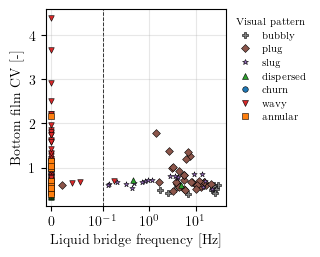

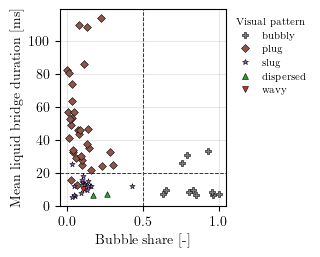

In [12]:
# Fig. 21a: family (intermittent vs. separated)
fig = criterion_scatter(
    features, 'bridge_freq_hz', 'film_est_cv',
    r'Liquid bridge frequency [Hz]', r'Bottom film CV [-]', styles,
    xlines=[P['f_bridge_hz']],
    xscale='symlog',
)
save(fig, 'fig21a_criterion_family')
display(fig)

# Fig. 21b: intermittent family
df_intermittent = features[features['bridge_freq_hz'] >= P['f_bridge_hz']].copy()
df_intermittent['bridge_mean_duration_ms'] = 1000 * df_intermittent['bridge_mean_duration_s']

fig = criterion_scatter(
    df_intermittent, 'bubble_share', 'bridge_mean_duration_ms',
    r'Bubble share [-]', r'Mean liquid bridge duration [ms]', styles,
    xlines=[P['bubble_share_min']],
    ylines=[1000 * P['plug_min_duration']],
)
save(fig, 'fig21b_criterion_intermittent')
display(fig)

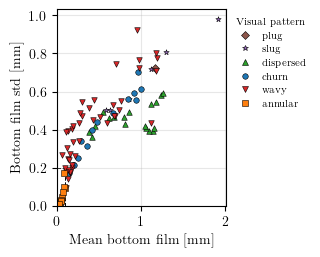

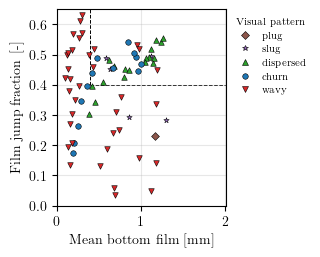

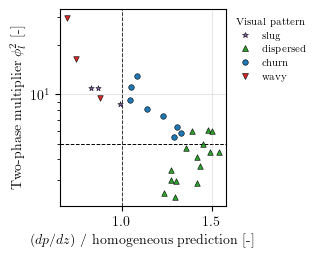

In [13]:
df_separated = features[features['bridge_freq_hz'] < P['f_bridge_hz']]

# Fig. 22a: annular box (mean vs. std of the bottom film)
mean_a, std_a = P['annular_max_mean'], P['annular_max_std']

fig = criterion_scatter(
    df_separated, 'film_est_mean_mm', 'film_est_std_mm',
    r'Mean bottom film [mm]', r'Bottom film std [mm]', styles,
    segments=[((mean_a, mean_a), (0, std_a)), ((0, mean_a), (std_a, std_a))],
    xlim=(0, 1.05 * df_separated['film_est_mean_mm'].max()),
    ylim=(0, 1.05 * df_separated['film_est_std_mm'].max()),
)
save(fig, 'fig22a_criterion_separated')
display(fig)

# Fig. 22b: thick and jumpy film (non-annular separated runs)
df_film = df_separated[df_separated['objective_pattern'] != 'annular']
mean_d, jump_d = P['dispersed_min_mean'], P['dispersed_min_jump']
x_max = 1.05 * df_film['film_est_mean_mm'].max()

fig = criterion_scatter(
    df_film, 'film_est_mean_mm', 'film_jump_frac',
    r'Mean bottom film [mm]', r'Film jump fraction [-]', styles,
    segments=[((mean_d, mean_d), (jump_d, 1.0)), ((mean_d, x_max), (jump_d, jump_d))],
    xlim=(0, x_max),
    ylim=(0, 0.65),
)
save(fig, 'fig22b_criterion_dispersed')
display(fig)

# Fig. 22c: pressure gate and dispersed / churn split (agitated films)
agitated_signature = (
    (features['n_peaks'] >= P['dispersed_min_peaks'])
    | (
        (features['film_est_mean_mm'] >= P['dispersed_min_mean'])
        & (features['film_jump_frac'] >= P['dispersed_min_jump'])
        & (1 - features['f_undetected'] >= P['dispersed_min_detected'])
    )
)
df_agitated = features[agitated_signature & (features['bridge_freq_hz'] < P['f_bridge_hz'])]

fig = criterion_scatter(
    df_agitated, 'ratio_homog', 'phi2_l',
    r'$(dp/dz)$ / homogeneous prediction [-]', r'Two-phase multiplier $\phi_l^2$ [-]', styles,
    xlines=[P['agitated_min_homog_ratio']],
    ylines=[P['dispersed_max_phi2']],
    yscale='log',
)
save(fig, 'fig22c_criterion_agitated')
display(fig)

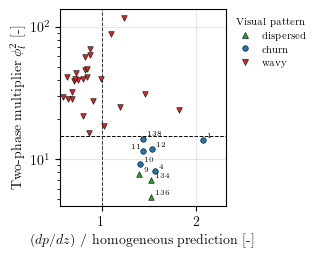

In [14]:
# Fig. 22d: liquid-rich branch (separated, neither annular nor agitated, thin film seen)
annular_film = (
    (features['film_est_mean_mm'].fillna(0) < P['annular_max_mean'])
    & (features['film_est_std_mm'].fillna(0) < P['annular_max_std'])
)

df_thin = features[
    (features['bridge_freq_hz'] < P['f_bridge_hz'])
    & ~annular_film
    & ~agitated_signature
    & (features['film_est_mean_mm'] < P['liquid_rich_max_film'])
].copy()

# Label only the high-velocity runs discussed in the text
LABELLED_RUNS = [1, 4, 138, 9, 134, 136, 10, 11, 12]
df_thin['label'] = np.where(df_thin['run_id'].isin(LABELLED_RUNS), df_thin['run_id'].astype(str), '')

fig = criterion_scatter(
    df_thin, 'ratio_homog', 'phi2_l',
    r'$(dp/dz)$ / homogeneous prediction [-]', r'Two-phase multiplier $\phi_l^2$ [-]', styles,
    xlines=[P['agitated_min_homog_ratio']],
    ylines=[P['liquid_rich_max_phi2']],
    yscale='log',
    xlim=(0.95 * df_thin['ratio_homog'].min(), 1.12 * df_thin['ratio_homog'].max()),
    label_column='label',
)

# Runs 11 and 12 are close: put the label of 11 on the left of its marker
for text in fig.axes[0].texts:
    if text.get_text() == '11':
        text.xyann = (-9, 2)

save(fig, 'fig22d_criterion_liquid_rich')
display(fig)

## Section 4.5: agreement with the visual classification

**Fig. 23**: confusion matrix, now with the same pattern order on both axes (the figure of kde_plots.ipynb has dispersed and churn swapped between rows and columns). **Fig. 24**: visual (157 runs, 7 reference classes) and objective maps, same markers. The region labels of the map are drawn above the markers with a white outline (the "wavy" label was hidden).

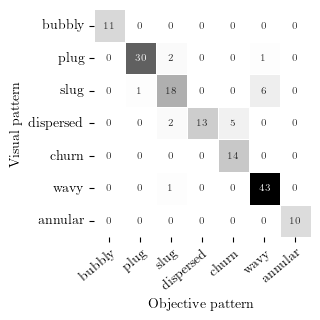

,bubbly,plug,slug,dispersed,churn,wavy,annular
bubbly,11,0,0,0,0,0,0
plug,0,30,2,0,0,1,0
slug,0,1,18,0,0,6,0
dispersed,0,0,2,13,5,0,0
churn,0,0,0,0,14,0,0
wavy,0,0,1,0,0,43,0
annular,0,0,0,0,0,0,10


In [15]:
confusion = pd.crosstab(features['reduced_pattern'], features['objective_pattern']).reindex(
    index=PATTERNS, columns=PATTERNS, fill_value=0
)

# Same counts as the confusion matrix of CRITERIA_VERSION
reference = pd.read_csv(results_path / 'confusion_matrix.csv', index_col=0).reindex(index=PATTERNS, columns=PATTERNS)
assert (confusion.to_numpy() == reference.to_numpy()).all()

confusion.index.name = None
confusion.columns.name = None

fig = confusion_heatmap(confusion)

# Rotated labels anchored at the tick, so dispersed and churn do not overlap
ax = fig.axes[0]
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right', rotation_mode='anchor')
fig.tight_layout()

save(fig, 'fig23_confusion_matrix')
display(fig)

confusion

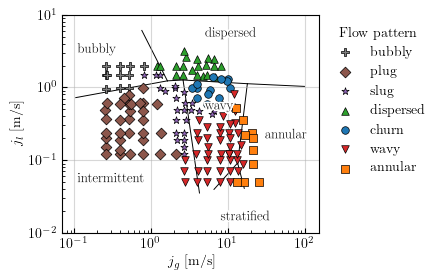

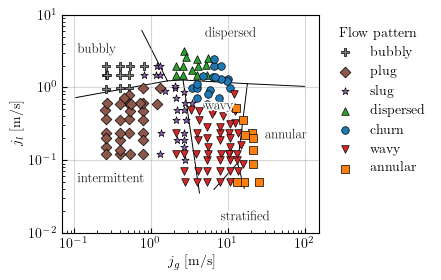

In [16]:
def pattern_map(df, column):
    """
    Flow pattern map of ``column`` (visual reference or objective pattern),
    legend in the order of PATTERNS, markers as in kde_plots.ipynb.
    """

    df_map = df[['run_id', 'jl', 'jg', column]].rename(columns={column: 'reduced_pattern'})
    df_map['reduced_pattern'] = pd.Categorical(df_map['reduced_pattern'], PATTERNS, ordered=True)
    df_map = df_map.sort_values('reduced_pattern')
    df_map['reduced_pattern'] = df_map['reduced_pattern'].astype(str)

    fig, ax = map_garimella(df_map, style_order=map_categories)

    # Region labels above the markers, with a white outline
    for text in ax.texts:
        text.set_zorder(4)
        text.set_path_effects([path_effects.withStroke(linewidth=2.5, foreground='white')])

    return fig


with plt.rc_context(MAP_RC):

    fig = pattern_map(features, 'reduced_pattern')
    save(fig, 'fig24a_flow_pattern_map_visual')
    display(fig)

    fig = pattern_map(features, 'objective_pattern')
    save(fig, 'fig24b_flow_pattern_map_objective')
    display(fig)

## Section 4.6: sensitivity

**Fig. 25**: balanced accuracy when one threshold varies (sweep of `CRITERIA_VERSION`, `sensitivity_thresholds.csv`), with shorter axis labels so they no longer overlap.

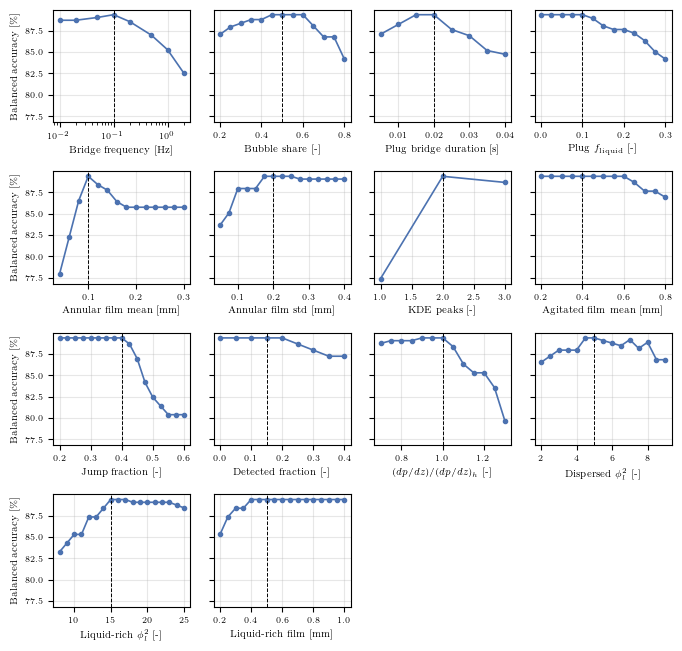

In [17]:
df_sweep = pd.read_csv(results_path / 'sensitivity_thresholds.csv')

SHORT_LABELS = {
    'f_bridge_hz': r'Bridge frequency [Hz]',
    'bubble_share_min': r'Bubble share [-]',
    'plug_min_duration': r'Plug bridge duration [s]',
    'plug_min_f_liquid': r'Plug $f_\mathrm{liquid}$ [-]',
    'annular_max_mean': r'Annular film mean [mm]',
    'annular_max_std': r'Annular film std [mm]',
    'dispersed_min_peaks': r'KDE peaks [-]',
    'dispersed_min_mean': r'Agitated film mean [mm]',
    'dispersed_min_jump': r'Jump fraction [-]',
    'dispersed_min_detected': r'Detected fraction [-]',
    'agitated_min_homog_ratio': r'$(dp/dz)/(dp/dz)_h$ [-]',
    'dispersed_max_phi2': r'Dispersed $\phi_l^2$ [-]',
    'liquid_rich_max_phi2': r'Liquid-rich $\phi_l^2$ [-]',
    'liquid_rich_max_film': r'Liquid-rich film [mm]',
}

fig = sweep_figure(df_sweep, P, SHORT_LABELS)
save(fig, 'fig25_sensitivity_thresholds')
display(fig)

## Checks

In [18]:
# The figures use the classification of CRITERIA_VERSION unchanged
balanced, agreement = balanced_accuracy(features['reduced_pattern'], features['objective_pattern'], OBJECTIVE_PATTERNS)

print(f'agreement {100 * agreement:.1f} %, balanced accuracy {100 * balanced:.1f} %')
reported = pd.read_csv(criteria_path / 'variant_comparison_criterion.csv', index_col=0).loc['processed_v2']
assert np.isclose(agreement, reported['agreement']) and np.isclose(balanced, reported['balanced_accuracy'])

print(f'{len(saved)} files in {out}:')
for name in saved:
    print('  ', name)

agreement 88.5 %, balanced accuracy 89.4 %
38 files in C:\Users\fernando\Downloads\projects\phd_paper\data\gold_layer\paper_figures:
   fig06_tube_thickness_before_treatment.pdf
   fig07_tube_thickness_after_treatment.pdf
   fig08_mixer_wave_removal_run46.pdf
   fig09_evaluated_region.pdf
   fig11_decision_tree.tex
   fig11_decision_tree.pdf
   fig12a_profile_bubbly_run65.pdf
   fig12b_profile_bubbly_run59.pdf
   fig13a_profile_plug_run33.pdf
   fig13b_profile_plug_run28.pdf
   fig14a_profile_slug_run67.pdf
   fig14b_profile_slug_run56.pdf
   fig15a_profile_dispersed_run8.pdf
   fig15b_profile_dispersed_run9.pdf
   fig16a_profile_wavy_run45.pdf
   fig16b_profile_wavy_run44.pdf
   fig17a_profile_churn_run93.pdf
   fig17b_profile_churn_liquid_rich_run1.pdf
   fig17c_profile_annular_run85.pdf
   fig18_bottom_film_by_pattern.pdf
   fig19_bottom_film_separated_zoom.pdf
   fig20_kde_by_pattern.pdf
   fig20a_kde_bubbly.pdf
   fig20b_kde_plug.pdf
   fig20c_kde_slug.pdf
   fig20d_kde_dispersed.